# Experiment 06: Optimizers at large batch

Card: [exp06_optimizers_large_batch.md](../../experiments/exp06_optimizers_large_batch.md)


In [1]:
import os
import sys

import lightning.pytorch as L
from lightning.pytorch.callbacks import EarlyStopping
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS
from ashrae.data import read_processed, split
from ashrae.features import build_features
from ashrae.metrics import rmsle
from ashrae.modeling import MeterMLP, make_loaders, predict
from ashrae.tracking import Experiment

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp06_optimizers_large_batch"
OPTIMIZERS = {  # no weight decay, so AdamW equals Adam
    "Adam": lambda lr: lambda params: torch.optim.Adam(params, lr=lr),
    "Momentum": lambda lr: lambda params: torch.optim.SGD(params, lr=lr, momentum=0.9),
    "Nesterov": lambda lr: lambda params: torch.optim.SGD(
        params, lr=lr, momentum=0.9, nesterov=True
    ),
}
EMB_DIM = 12  # picked in exp03
if SMOKE:
    EXPERIMENT = "ashrae-mlp-optimizers-large-batch-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS, WINDOW = 3, 1
    BATCH_SIZES = [8192, 16384]
    LRS = {
        "Adam": [3e-3, 1e-2, 3e-2, 1e-1],
        "Momentum": [1e-2, 3e-2, 1e-1, 3e-1],
        "Nesterov": [1e-2, 3e-2, 1e-1, 3e-1],
    }
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-optimizers-large-batch"
    TRAIN = False  # trained in the session below; True trains only runs it lacks
    SESSION = "2026-10-12 19:15:33"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    WINDOW = (
        5  # epochs before the best one over which the epoch-to-epoch change is averaged
    )
    BATCH_SIZES = [8192, 16384]
    LRS = {  # inner rates start at exp05's best rate at batch 4096 and go up
        "Adam": [3e-3, 1e-2, 3e-2, 1e-1, 3e-1],
        "Momentum": [1e-2, 3e-2, 1e-1, 3e-1, 1.0],
        "Nesterov": [1e-2, 3e-2, 1e-1, 3e-1, 1.0],
    }
    FIGURE = "../../figures/exp06_optimizers_large_batch.png"
# the first and last rate of each grid are trained only if the best inner rate is next to them

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/12 19:15:33 INFO mlflow.tracking.fluent: Experiment with name 'ashrae-mlp-optimizers-large-batch' does not exist. Creating a new experiment.


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-optimizers-large-batch', session 2026-10-12 19:15:33


## Training


In [ ]:
def at_best(run_id):
    """A run's scores at its best validation epoch, plus its per-epoch curves; a diverged run scores inf."""
    val = np.array(experiment.history(run_id, "val_rmsle"))
    train = np.array(experiment.history(run_id, "train_rmsle"))
    if not np.isfinite(val).all():
        return {
            "best_epoch": np.nan,
            "val": np.inf,
            "val_clean": np.inf,
            "train": np.inf,
            "change": np.nan,
            "val_curve": val,
            "train_curve": train,
        }
    b = int(val.argmin())
    return {
        "best_epoch": b + 1,
        "val": val[b],
        "val_clean": experiment.history(run_id, "val_rmsle_clean")[b],
        "train": train[b],
        "change": (
            np.abs(np.diff(val[max(b - WINDOW, 0) : b + 1])).mean() if b else np.nan
        ),
        "val_curve": val,
        "train_curve": train,
    }


def scores():
    runs = experiment.runs().rename(columns=lambda c: c.removeprefix("tags."))
    runs = runs[runs.status == "FINISHED"]  # an interrupted run is retrained
    scored = pd.DataFrame([at_best(r) for r in runs.run_id], index=runs.index)
    runs = runs[["run_id", "batch_size", "optimizer", "lr", "fold"]].assign(
        batch_size=lambda r: r.batch_size.astype(int), lr=lambda r: r.lr.astype(float)
    )
    return pd.concat([runs, scored], axis=1)


class CleanRMSLE(L.Callback):
    """Logs validation RMSLE on the clean rows after every epoch, so it can be read at the best epoch."""

    def __init__(self, loader, y):
        self.loader, self.y = loader, y

    def on_validation_epoch_end(self, trainer, model):
        if not trainer.sanity_checking:
            model.log("val_rmsle_clean", rmsle(self.y, predict(model, self.loader)))

In [3]:
if TRAIN:
    df = read_processed()
    n_buildings = int(df.building_id.max()) + 1
    folds = {}
    for fold in FOLD_NAMES:
        train_df, val_df = split(df, FOLDS[fold], N_TRAIN, N_VAL)
        year_median = train_df.year_built.median()
        X_train, X_val = build_features(train_df, year_median), build_features(
            val_df, year_median
        )
        clean = ~val_df.anomaly.to_numpy()
        folds[fold] = {
            "loaders": make_loaders(train_df, val_df, X_train, X_val)[:2],
            "clean": (
                make_loaders(train_df, val_df[clean], X_train, X_val[clean])[1],
                np.log1p(val_df.meter_reading.to_numpy(dtype="float32")[clean]),
            ),
        }
    del df
    n_features = X_train.shape[1]
    done = (
        set()
        if SESSION is None
        else set(
            scores()[["batch_size", "optimizer", "lr", "fold"]].itertuples(index=False)
        )
    )

    def train(batch_size, optimizer, lr):
        for fold, d in folds.items():
            if (batch_size, optimizer, lr, fold) in done:
                continue
            train_loader, val_loader = d["loaders"]
            # same scaled rows for every size, only the batching changes
            train_loader = DataLoader(
                train_loader.dataset,
                batch_size=batch_size,
                shuffle=True,
                collate_fn=train_loader.collate_fn,
            )
            experiment.fit(
                lambda: MeterMLP(n_features, n_buildings, emb_dim=EMB_DIM),
                train_loader,
                val_loader,
                run_name=f"mlp_4out_emb | batch {batch_size} | {optimizer} lr {lr:g} | {fold}",
                epochs=EPOCHS,
                lr=lr,  # recorded only: the optimizer below sets the rate
                optimizer=OPTIMIZERS[optimizer](lr),
                callbacks=[
                    CleanRMSLE(*d["clean"]),
                    # stops a diverged run only: patience never runs out
                    EarlyStopping("val_rmsle", patience=EPOCHS, check_finite=True),
                ],
                tags={
                    "fold": fold,
                    "model": "mlp_4out_emb",
                    "batch_size": str(batch_size),
                    "optimizer": optimizer,
                    "lr": f"{lr:g}",
                },
                params={"n_train": N_TRAIN, "n_val": N_VAL, "emb_dim": EMB_DIM},
            )

    for batch_size in BATCH_SIZES:
        for optimizer, lrs in LRS.items():
            for lr in lrs[1:-1]:
                train(batch_size, optimizer, lr)
    grid = scores()
    for batch_size in BATCH_SIZES:
        for optimizer, lrs in LRS.items():
            inner = grid[
                (grid.batch_size == batch_size)
                & (grid.optimizer == optimizer)
                & grid.lr.isin(lrs[1:-1])
            ]
            best = inner.groupby("lr").val.mean().idxmin()
            if best == lrs[1]:
                train(batch_size, optimizer, lrs[0])
            elif best == lrs[-2]:
                train(batch_size, optimizer, lrs[-1])

mlp_4out_emb | batch 8192 | Adam lr 0.01 | Jan–Mar: 100%|██████████| 9800/9800 [00:50<00:00, 195.38batch/s, epoch 40, val 1.4122, best 1.4005 at 38]
mlp_4out_emb | batch 8192 | Adam lr 0.01 | Apr–Jun: 100%|██████████| 9800/9800 [00:48<00:00, 200.04batch/s, epoch 40, val 1.2199, best 1.2036 at 23]
mlp_4out_emb | batch 8192 | Adam lr 0.01 | Jul–Sep: 100%|██████████| 9800/9800 [00:49<00:00, 199.34batch/s, epoch 40, val 1.0424, best 1.0243 at 19]
mlp_4out_emb | batch 8192 | Adam lr 0.01 | Oct–Dec: 100%|██████████| 9800/9800 [00:49<00:00, 197.53batch/s, epoch 40, val 1.0931, best 1.0931 at 40]
mlp_4out_emb | batch 8192 | Adam lr 0.03 | Jan–Mar: 100%|██████████| 9800/9800 [00:49<00:00, 198.00batch/s, epoch 40, val 1.4182, best 1.3945 at 17]
mlp_4out_emb | batch 8192 | Adam lr 0.03 | Apr–Jun: 100%|██████████| 9800/9800 [00:49<00:00, 198.37batch/s, epoch 40, val 1.2217, best 1.1983 at 25]
mlp_4out_emb | batch 8192 | Adam lr 0.03 | Jul–Sep: 100%|██████████| 9800/9800 [00:49<00:00, 197.45batch/s

## Results


In [4]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs")

columns = {
    "val_clean": "average, clean rows",
    "best_epoch": "best epoch",
    "train": "training",
    "change": "epoch-to-epoch change",
}
keys = ["batch_size", "optimizer", "lr"]
by_lr = results.groupby(keys)[["val", *columns]].mean()
table = results.pivot_table(index=keys, columns="fold", values="val", dropna=False)[
    FOLD_NAMES
]
table["average"] = by_lr.val
table = table.join(by_lr[list(columns)].rename(columns=columns))
display(
    table.round(3).rename_axis(
        columns="RMSLE at the best epoch, all rows unless noted (inf = diverged)"
    )
)

best_lr = {
    (b, o): by_lr.loc[(b, o)].val.idxmin() for b in BATCH_SIZES for o in OPTIMIZERS
}
display(
    table.loc[[(b, o, lr) for (b, o), lr in best_lr.items()]]
    .round(3)
    .rename_axis(columns="each optimizer at its best lr")
)

MLflow session 2026-10-12 19:15:33: 80 runs


RMSLE at the best epoch, all rows unless noted (inf = diverged)  Jan–Mar  \
batch_size optimizer lr                                                    
8192       Adam      0.01                                          1.401   
                     0.03                                          1.395   
                     0.10                                          1.397   
                     0.30                                            NaN   
           Momentum  0.01                                          1.422   
                     0.03                                          1.420   
                     0.10                                          1.425   
                     0.30                                          2.247   
           Nesterov  0.01                                          1.427   
                     0.03                                          1.408   
                     0.10                                          1.418   
                     0.30                                          2.240   
16384      Adam      0.01                                          1.399   
                     0.03                                          1.388   
                     0.10                                          1.384   
                     0.30                                            NaN   
           Momentum  0.01                                            NaN   
                     0.03                                          1.428   
                     0.10                                          1.419   
                     0.30                                          2.197   
           Nesterov  0.01                                            NaN   
                     0.03                                          1.426   
                     0.10                                          1.417   
                     0.30                                          2.257   

RMSLE at the best epoch, all rows unless noted (inf = diverged)  Apr–Jun  \
batch_size optimizer lr                                                    
8192       Adam      0.01                                          1.204   
                     0.03                                          1.198   
                     0.10                                          1.205   
                     0.30                                            NaN   
           Momentum  0.01                                          1.230   
                     0.03                                          1.226   
                     0.10                                          1.228   
                     0.30                                          1.805   
           Nesterov  0.01                                          1.224   
                     0.03                                          1.224   
                     0.10                                          1.226   
                     0.30                                            inf   
16384      Adam      0.01                                          1.205   
                     0.03                                          1.200   
                     0.10                                          1.198   
                     0.30                                            NaN   
           Momentum  0.01                                            NaN   
                     0.03                                          1.231   
                     0.10                                          1.231   
                     0.30                                          2.086   
           Nesterov  0.01                                            NaN   
                     0.03                                          1.230   
                     0.10                                          1.229   
                     0.30                                          2.091   

RMSLE at the best epoch, all rows unless noted

each optimizer at its best lr  Jan–Mar  Apr–Jun  Jul–Sep  Oct–Dec  average  \
batch_size optimizer lr                                                      
8192       Adam      0.03        1.395    1.198    1.015    1.086    1.173   
           Momentum  0.03        1.420    1.226    1.065    1.111    1.205   
           Nesterov  0.03        1.408    1.224    1.061    1.115    1.202   
16384      Adam      0.03        1.388    1.200    1.020    1.092    1.175   
           Momentum  0.10        1.419    1.231    1.083    1.117    1.213   
           Nesterov  0.10        1.417    1.229    1.069    1.115    1.207   

each optimizer at its best lr  average, clean rows  best epoch  training  \
batch_size optimizer lr                                                    
8192       Adam      0.03                    0.923       22.50     0.783   
           Momentum  0.03                    0.951       38.25     0.835   
           Nesterov  0.03                    0.950       34.25     0.832   
16384      Adam      0.03                    0.930       24.50     0.791   
           Momentum  0.10                    0.963       36.75     0.850   
           Nesterov  0.10                    0.959       34.50     0.852   

each optimizer at its best lr  epoch-to-epoch change  
batch_size optimizer lr                               
8192       Adam      0.03                      0.013  
           Momentum  0.03                      0.010  
           Nesterov  0.03                      0.012  
16384      Adam      0.03                      0.013  
           Momentum  0.10                      0.013  
           Nesterov  0.10                      0.023

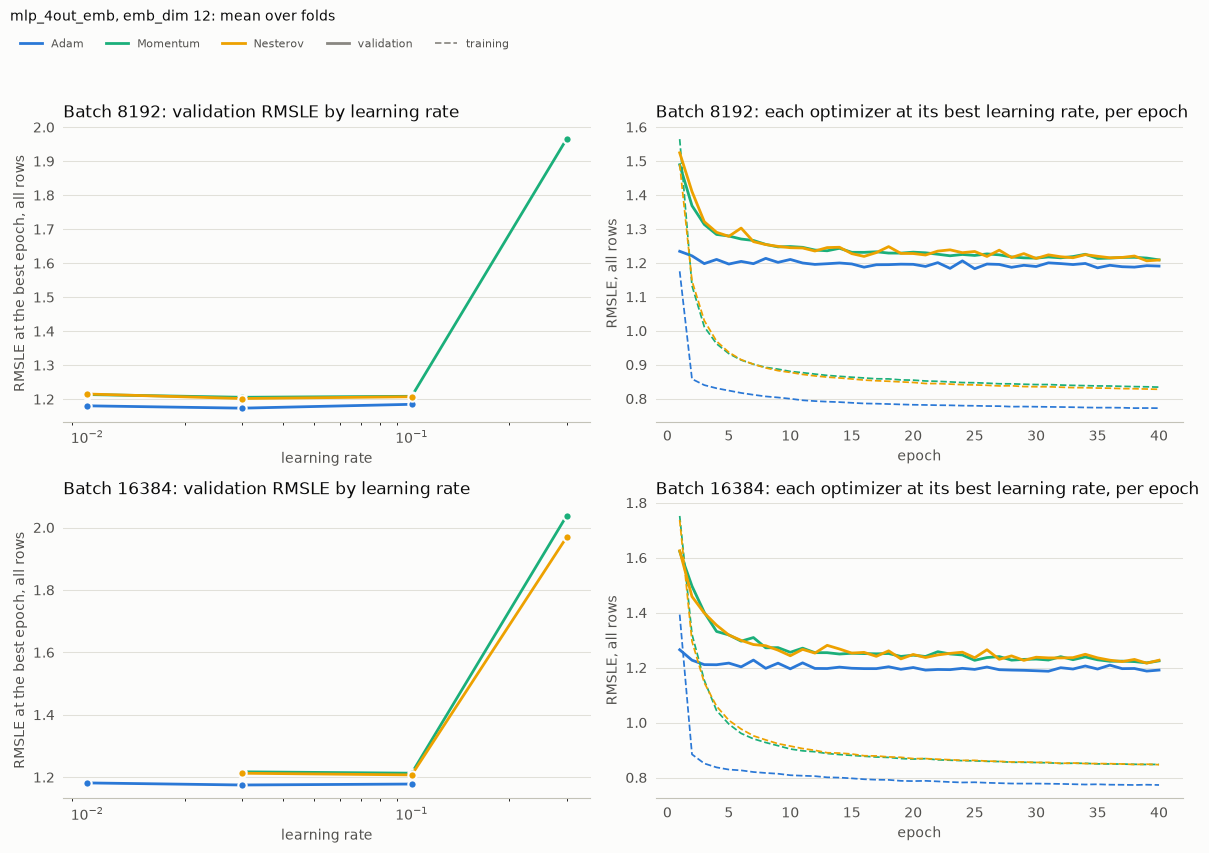

In [5]:
INK, TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLORS = dict(zip(OPTIMIZERS, ["#2a78d6", "#1baf7a", "#eda100"]))

fig, axes = plt.subplots(
    len(BATCH_SIZES), 2, figsize=(12, 4.2 * len(BATCH_SIZES)), facecolor=SURFACE
)
for (ax_lr, ax_ep), batch_size in zip(axes, BATCH_SIZES):
    for optimizer, color in COLORS.items():
        curve = by_lr.loc[(batch_size, optimizer)].val
        curve = curve[np.isfinite(curve)]  # a diverged rate has no point
        ax_lr.plot(
            curve.index,
            curve,
            color=color,
            lw=2,
            marker="o",
            ms=6,
            mec=SURFACE,
            mew=1.5,
        )
        runs = results[
            (results.batch_size == batch_size)
            & (results.optimizer == optimizer)
            & (results.lr == best_lr[(batch_size, optimizer)])
        ]
        for key, ls in [("val_curve", "-"), ("train_curve", "--")]:
            mean = np.mean(runs[key].tolist(), axis=0)
            ax_ep.plot(
                np.arange(1, len(mean) + 1),
                mean,
                color=color,
                lw=2 if ls == "-" else 1.25,
                ls=ls,
            )
    ax_lr.set(
        xscale="log", xlabel="learning rate", ylabel="RMSLE at the best epoch, all rows"
    )
    ax_lr.set_title(
        f"Batch {batch_size}: validation RMSLE by learning rate", loc="left", color=INK
    )
    ax_ep.set(xlabel="epoch", ylabel="RMSLE, all rows")
    ax_ep.set_title(
        f"Batch {batch_size}: each optimizer at its best learning rate, per epoch",
        loc="left",
        color=INK,
    )
for ax in axes.flat:
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, lw=0.75)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, labelcolor=TEXT, length=0, pad=6)
    ax.xaxis.label.set_color(TEXT)
    ax.yaxis.label.set_color(TEXT)
handles = [
    *(Line2D([], [], color=c, lw=2, label=o) for o, c in COLORS.items()),
    Line2D([], [], color=MUTED, lw=2, label="validation"),
    Line2D([], [], color=MUTED, lw=1.25, ls="--", label="training"),
]
fig.legend(
    handles=handles,
    ncol=5,
    frameon=False,
    fontsize=8,
    labelcolor=TEXT,
    loc="lower left",
    bbox_to_anchor=(0.01, 0.95),
)
fig.suptitle(
    f"mlp_4out_emb, emb_dim {EMB_DIM}: mean over folds",
    x=0.01,
    ha="left",
    color=INK,
    fontsize=10,
    y=1.01,
)
plt.tight_layout(rect=(0, 0, 1, 0.95))
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.run_id:
        experiment.client.log_artifact(run_id, FIGURE)